In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from io import StringIO

%matplotlib inline

url = "https://uk.wikipedia.org/wiki/Населення_України"

response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"})
response.raise_for_status()

df = pd.read_html(StringIO(response.text))[12]

In [87]:
df.head()


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—


In [88]:
df.shape

(28, 9)

In [89]:
df = df.replace("—", np.nan)
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,NaN,NaN
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,NaN


In [90]:
df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,int64
2000,int64
2012,int64
2014,object
2019,object


In [91]:
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [92]:
df.isnull().sum() / len(df) * 100

,0
Регіон,0.000000
1950,7.142857
1960,3.571429
1970,3.571429
1990,0.000000
2000,0.000000
2012,0.000000
2014,7.142857
2019,14.285714


In [93]:
avg_2019 = df.iloc[-1]["2019"]

df = df.iloc[:-1]
df.tail()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
22,Черкаська,205.0,179.0,144.0,123,75,100,98.0,64.0
23,Чернівецька,247.0,218.0,170.0,148,101,128,129.0,92.0
24,Чернігівська,220.0,183.0,127.0,108,69,94,90.0,61.0
25,Київ,NaN,174.0,159.0,120,73,120,121.0,110.0
26,Севастополь,NaN,NaN,NaN,125,70,120,NaN,NaN


In [94]:
numeric_cols = df.columns[1:]

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].mean()
)

df.isnull().sum()

,0
Регіон,0
1950,0
1960,0
1970,0
1990,0
2000,0
2012,0
2014,0
2019,0


In [95]:
df.loc[df["2019"] > avg_2019, ["Регіон", "2019"]]

,Регіон,2019
2,Волинська,101.0
6,Закарпатська,104.0
8,Івано-Франківська,88.0
12,Львівська,87.0
14,Одеська,88.0
16,Рівненська,107.0
23,Чернівецька,92.0
25,Київ,110.0


In [96]:
df.loc[df["2014"].idxmax(), ["Регіон", "2014"]]

,16
Регіон,Рівненська
2014,148.0


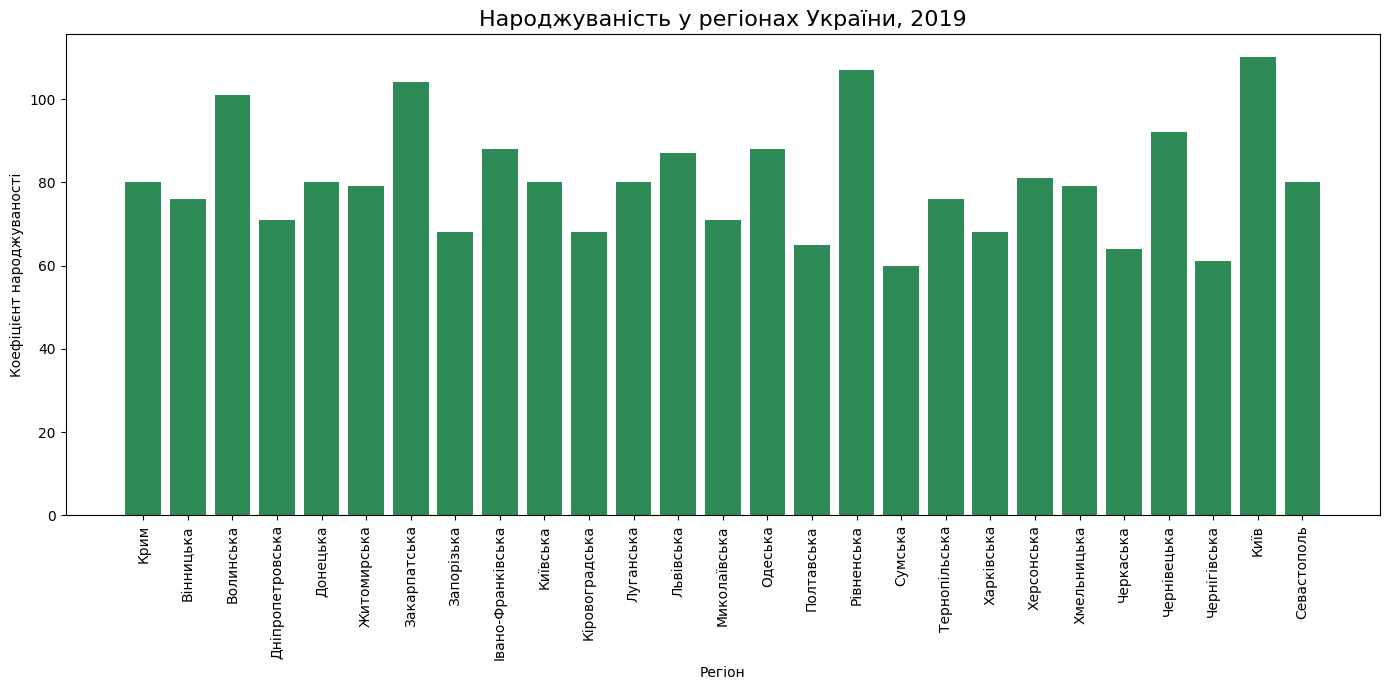

In [97]:
plt.figure(figsize=(14, 7))

plt.bar(df["Регіон"], df["2019"], color="seagreen")

plt.title("Народжуваність у регіонах України, 2019", fontsize=16)
plt.xlabel("Регіон")
plt.ylabel("Коефіцієнт народжуваності")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

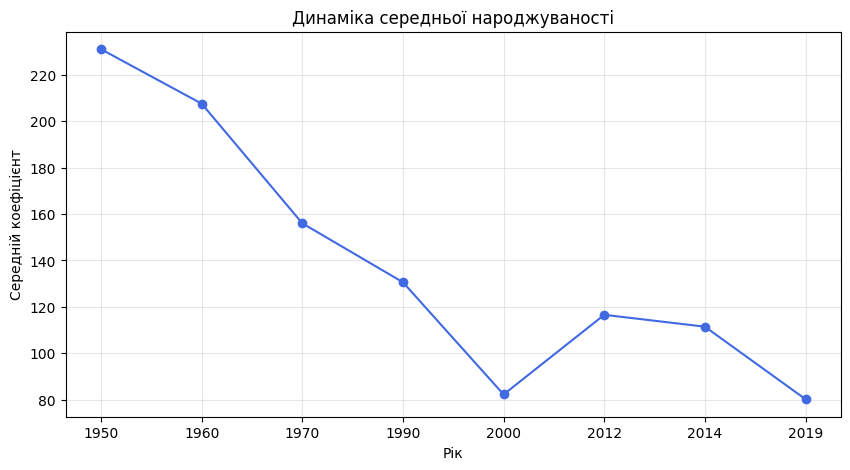

In [98]:
years = df.columns[1:]
avg_birth = df[years].mean()

plt.figure(figsize=(10, 5))

plt.plot(years, avg_birth, marker="o", color="royalblue")

plt.title("Динаміка середньої народжуваності")
plt.xlabel("Рік")
plt.ylabel("Середній коефіцієнт")
plt.grid(True, alpha=0.3)

plt.show()

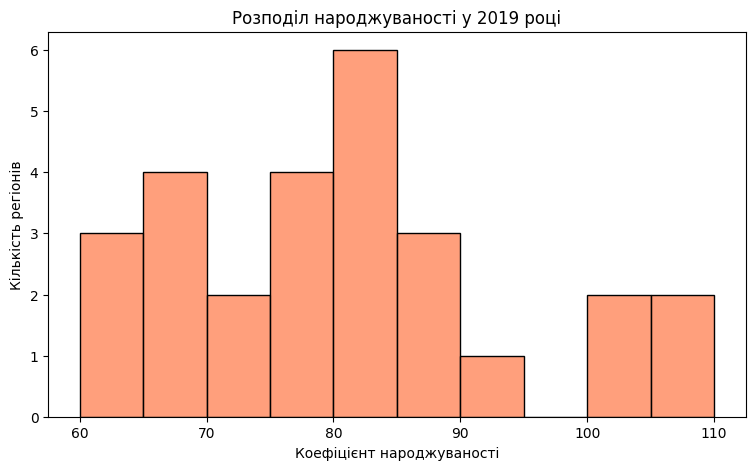

In [99]:
plt.figure(figsize=(9, 5))

sns.histplot(df["2019"], bins=10, color="coral", edgecolor="black")

plt.title("Розподіл народжуваності у 2019 році")
plt.xlabel("Коефіцієнт народжуваності")
plt.ylabel("Кількість регіонів")

plt.show()

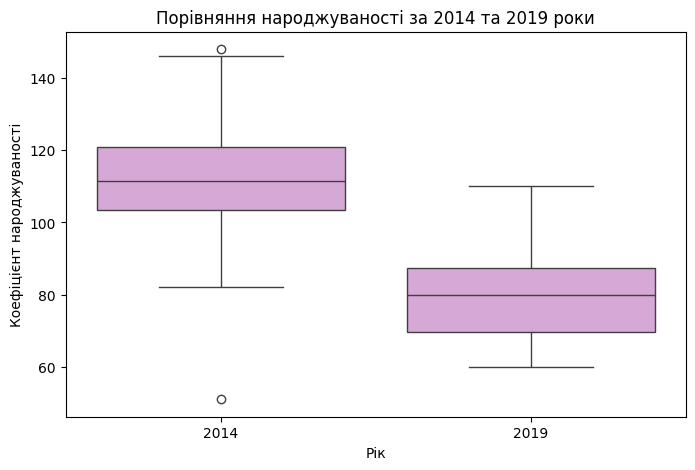

In [100]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[["2014", "2019"]], color="plum")

plt.title("Порівняння народжуваності за 2014 та 2019 роки")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності")

plt.show()